# 03 · Where riders lose the most time, and what to build

Notebook 02 measured delay per bus. This notebook weights it by how many riders are on board, groups segments into
corridors (connected stretches of the same street), checks each corridor's bus lane coverage, compares the results with
the MBTA's own bus priority plans, and sorts the top 20 into recommendations.

Run notebook 02 first: this one uses the tables it saved in `data/analysis.duckdb`.

In [2]:
import os, sys
from pathlib import Path
import duckdb

# find the project folder (the one containing scripts/) from wherever this notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "corridors.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

con = duckdb.connect("data/analysis.duckdb")

## Riders on board

MBTA ridership (Fall 2025, `data/bus_ridership.csv`) gives the average load leaving each stop on each trip.
Averaging weekday trips that start between 3 and 7pm gives the typical number of riders on board leaving each stop in the
evening rush. The riders stuck in a segment's delay are the load at its first stop, so:

rider-minutes lost = delay per bus × buses per day × riders on board

In [3]:
con.sql("""
CREATE OR REPLACE TABLE stop_load AS
SELECT "GTFS stop_id" AS stop_id,
       avg(try_cast("Load" AS DOUBLE)) AS avg_load,
       count(*) AS trips
FROM read_csv('data/bus_ridership.csv', all_varchar = true)
WHERE "Day Type" = 'Wkdy'
  AND try_cast(split_part("trip start time", ':', 1) AS INT) BETWEEN 15 AND 18
GROUP BY ALL
""")

con.sql("""
SELECT f.stop_name AS from_stop, t.stop_name AS to_stop, s.routes,
       round(pm_secs - night_secs) AS delay_per_bus,
       round(pm_n / 5.0) AS buses_per_day,
       round(l.avg_load, 1) AS riders_on_board,
       round((pm_secs - night_secs) * pm_n / 5.0 * l.avg_load / 60) AS rider_minutes_lost
FROM seg_stats s
JOIN stop_load l ON l.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) f ON f.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) t ON t.stop_id = s.to_stop_id
WHERE night_n >= 15 AND pm_n >= 25
ORDER BY rider_minutes_lost DESC
LIMIT 20
""").show(max_rows=25)

┌─────────────────────────────────┬───────────────────────────────────────┬────────────────────────────┬───────────────┬───────────────┬─────────────────┬────────────────────┐
│            from_stop            │                to_stop                │           routes           │ delay_per_bus │ buses_per_day │ riders_on_board │ rider_minutes_lost │
│             varchar             │                varchar                │          varchar           │    double     │    double     │     double      │       double       │
├─────────────────────────────────┼───────────────────────────────────────┼────────────────────────────┼───────────────┼───────────────┼─────────────────┼────────────────────┤
│ N Washington St @ Cooper St     │ Beacon St @ Broadway                  │ 111                        │         136.0 │          28.0 │            29.9 │             1930.0 │
│ Meridian St @ Falcon St         │ Pearl St @ Marginal St                │ 116, 114                   │         177.0 │

Counting riders moves the bridges to the top: the Tobin outbound (111), the Chelsea St Bridge (114, 116) and the
Anderson Bridge at Harvard (66, 86). Nubian drops from first to sixth: many buses, but fewer riders on each.

## Corridors

A lane goes on a street, not a single hop, so segments are grouped into corridors (`corridors.py`):
same street name, same town, and physically connected (stops within 150 m). Each corridor gets a readable label
from its end cross streets, its length, and the share of its segments that already have a bus lane in the bus's direction.
The Silver Line tunnel routes (SL1 to SL3) are left out since they don't run in street traffic.

In [4]:
import json
from corridors import build_corridors, load_lanes, classify

with open("data/mbta_bus_lanes.geojson") as f:
    lanes_gj = json.load(f)
lane_parts = load_lanes(lanes_gj)

seg = con.sql("""
SELECT f.stop_name AS f, t.stop_name AS t,
       coalesce(f.municipality, '') AS town,
       s.routes, s.from_stop_id, s.to_stop_id,
       try_cast(f.stop_lon AS DOUBLE) AS lon1, try_cast(f.stop_lat AS DOUBLE) AS lat1,
       try_cast(t.stop_lon AS DOUBLE) AS lon2, try_cast(t.stop_lat AS DOUBLE) AS lat2,
       (pm_secs - night_secs) * pm_n / 5.0 * l.avg_load / 60 AS rider_min
FROM seg_stats s
JOIN stop_load l ON l.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) f ON f.stop_id = s.from_stop_id
JOIN read_csv('data/gtfs/stops.txt', all_varchar = true) t ON t.stop_id = s.to_stop_id
WHERE night_n >= 15 AND pm_n >= 25
  AND NOT regexp_full_match(s.routes, '74[1236](, 74[1236])*')
""").df().dropna()

seg["lane_type"] = [classify(lane_parts, *r) for r in zip(seg.lon1, seg.lat1, seg.lon2, seg.lat2)]

corr, seg = build_corridors(seg, return_segments=True)
corr["rider_hours"] = (corr.rider_minutes_lost / 60).round(1)
corr["hours_per_mile"] = (corr.rider_hours / corr.miles.clip(lower=0.25)).round(1)

# saved for export_for_blender.py
con.register("corr_df", corr)
con.sql("CREATE OR REPLACE TABLE corridors AS SELECT * FROM corr_df")
con.register("corr_seg_df", seg)
con.sql("CREATE OR REPLACE TABLE corridor_segments AS SELECT * FROM corr_seg_df")

print(corr[["corridor", "town", "rider_hours", "miles", "hours_per_mile",
            "pct_lane", "pct_unsure", "routes"]].head(20).to_string())

                                             corridor       town  rider_hours  miles  hours_per_mile  pct_lane  pct_unsure                               routes
0             Blue Hill Ave: Mattapan Sq to Gaston St     Boston         63.7   3.15            20.2         0           0           14, 22, 23, 28, 29, 31, 45
1   Massachusetts Ave: Newmarket Station to Beacon St     Boston         54.2   2.10            25.8         0           0                             1, 8, 10
2             Warren St: Crawford St to Kearsarge Ave     Boston         48.0   1.16            41.4         0           0                   14, 19, 23, 28, 44
3            Hyde Park Ave: Pingree St to Cummins Hwy     Boston         43.2   1.76            24.5         0           0                           14, 32, 50
4            Washington St: Sumner St to Tollgate Way     Boston         38.2   3.60            10.6        14          17  30, 34, 35, 36, 37, 40, 50, 51, 34E
5                  Harvard St: Kent St t

## What kind of fix each corridor needs

- Spot fix (choke point): shorter than 0.75 mile, or a single hop (bridges, squares). Signal priority, queue jumps or
  bridge treatments rather than a full lane.
- Extend existing lanes: at least 15% of the corridor already has a lane (counting lanes of unknown direction).
- Build new lanes: everything else.

## How this compares with the MBTA's plans

The MBTA's bus priority map (built by Nelson Nygaard) has two more layers besides existing lanes: planned/underway and
new bus priority needed. Both are downloaded from the same public ArcGIS service and saved to `data/`. A corridor counts
as on a layer when at least 30% of its segments sit within 40 m of it.

In [5]:
import requests
from shapely.geometry import LineString, Point
from shapely.ops import unary_union
from corridors import xy, fix_type

LAYERS = {
    "needed":  "https://services5.arcgis.com/MzDTvcMx2K6Svy8O/arcgis/rest/services/New_Bus_Priority_Needed/FeatureServer/9",
    "planned": "https://services5.arcgis.com/MzDTvcMx2K6Svy8O/arcgis/rest/services/Bus_Priority_Planned_Underway/FeatureServer/8",
}
nets = {}
for name, url in LAYERS.items():
    gj = requests.get(f"{url}/query", params={"where": "1=1", "outFields": "*",
                      "outSR": 4326, "f": "geojson"}, timeout=60).json()
    with open(f"data/mbta_priority_{name}.geojson", "w") as f:
        json.dump(gj, f)
    lines = []
    for feat in gj["features"]:
        g = feat["geometry"]
        parts = [g["coordinates"]] if g["type"] == "LineString" else g["coordinates"]
        lines += [LineString([xy(x, y) for x, y in p]) for p in parts]
    nets[name] = unary_union(lines)

def on_layer(net, r, near_m=40):
    return (net.distance(Point(xy(r.lon1, r.lat1))) <= near_m and
            net.distance(Point(xy(r.lon2, r.lat2))) <= near_m)

for name, net in nets.items():
    seg[f"on_{name}"] = [on_layer(net, r) for r in seg.itertuples()]
cov = (seg.groupby("corridor_id")[["on_needed", "on_planned"]].mean() * 100).round()

top = corr.head(20).copy()
top["rank"] = range(1, len(top) + 1)
top["fix"] = top.apply(fix_type, axis=1)
top = top.merge(cov, left_on="corridor_id", right_index=True, how="left")

def mbta_view(r):
    if r.on_planned >= 30: return "Already planned"
    if r.on_needed >= 30:  return "Agency agrees"
    if r.pct_lane + r.pct_unsure >= 15: return "Has lanes, still slow"
    return "New finding"
top["mbta_view"] = top.apply(mbta_view, axis=1)

print(top[["rank", "corridor", "town", "fix", "rider_hours", "pct_lane",
           "on_needed", "on_planned", "mbta_view"]].to_string(index=False))
print()
print(top.mbta_view.value_counts().to_string())

 rank                                          corridor      town                    fix  rider_hours  pct_lane  on_needed  on_planned             mbta_view
    1           Blue Hill Ave: Mattapan Sq to Gaston St    Boston        Build new lanes         63.7         0        0.0        92.0       Already planned
    2 Massachusetts Ave: Newmarket Station to Beacon St    Boston        Build new lanes         54.2         0       65.0         0.0         Agency agrees
    3           Warren St: Crawford St to Kearsarge Ave    Boston        Build new lanes         48.0         0        0.0       100.0       Already planned
    4          Hyde Park Ave: Pingree St to Cummins Hwy    Boston        Build new lanes         43.2         0      100.0         0.0         Agency agrees
    5          Washington St: Sumner St to Tollgate Way    Boston  Extend existing lanes         38.2        14       44.0         0.0         Agency agrees
    6                Harvard St: Kent St to Verndale St Br

Findings:
- 12 of the top 20 are on the MBTA's planned or needed lists, including #1 Blue Hill Ave and #3 Warren St, which together
  are the path of the 28 from Mattapan to Nubian and are already planned for center-running lanes. The method finds real problems.
- 3 already have lanes but still lose 23 to 35 rider-hours a weekday evening (Broadway in Everett, Washington St in the
  South End, Huntington Ave). The MBTA map counts them as done.
- 5 are on no MBTA list: Dudley St, Tremont St in Mission Hill, the Tobin Bridge outbound, Ave Louis Pasteur in Longwood,
  and Malcolm X Blvd into Nubian. Three cluster around Nubian and Longwood, suggesting a gap in central Roxbury.

## The map

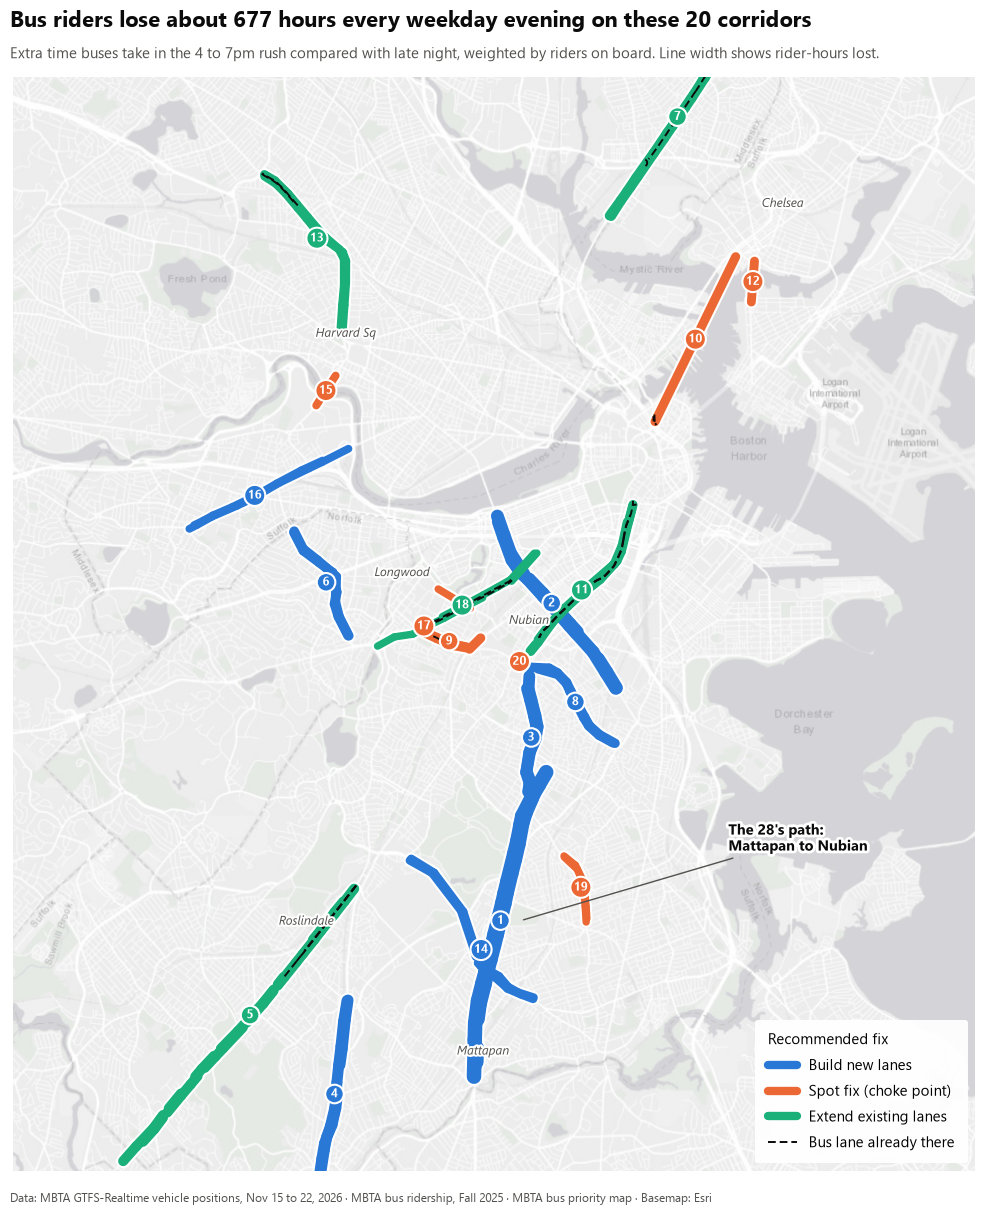

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import contextily as cx
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from corridors import K, L, FIX_COLORS

plt.rcParams["font.family"] = ["Segoe UI", "Arial", "DejaVu Sans"]
INK, INK_2 = "#0b0b0b", "#52514e"
total_hours = top.rider_hours.sum()

fig, ax = plt.subplots(figsize=(11, 12.5))
fig.patch.set_facecolor("white")
ax.set_xlim(-71.185, -70.995)
ax.set_ylim(42.255, 42.415)
cx.add_basemap(ax, crs="EPSG:4326", source=cx.providers.Esri.WorldGrayCanvas,
               zoom=13, attribution=False, alpha=0.9)

# corridors: white outline first, then color, so neighbors stay distinct
for r in top.itertuples():
    s = seg[seg.corridor_id == r.corridor_id]
    lines = [[(a, b), (c, d)] for a, b, c, d in zip(s.lon1, s.lat1, s.lon2, s.lat2)]
    w = 2.5 + r.rider_hours / 8
    ax.add_collection(LineCollection(lines, colors="white", linewidths=w + 3,
                                     capstyle="round", joinstyle="round", zorder=3))
    ax.add_collection(LineCollection(lines, colors=FIX_COLORS[r.fix], linewidths=w,
                                     capstyle="round", joinstyle="round", zorder=4))

# existing lanes, only where they overlap a recommended corridor
top_seg = seg[seg.corridor_id.isin(top.corridor_id)]
zone = unary_union([LineString([xy(a, b), xy(c, d)]) for a, b, c, d in
                    zip(top_seg.lon1, top_seg.lat1, top_seg.lon2, top_seg.lat2)]).buffer(60)
skip = ("I-93", "Tobin", "Haul Road", "Silver Line Way", "SL3", "Alewife")
lane_lines = []
for feat in lanes_gj["features"]:
    if any(s in feat["properties"]["Name"] for s in skip):
        continue
    g = feat["geometry"]
    for p in [g["coordinates"]] if g["type"] == "LineString" else g["coordinates"]:
        clip = LineString([xy(x, y) for x, y in p]).intersection(zone)
        for piece in getattr(clip, "geoms", [clip]):
            if piece.geom_type == "LineString" and piece.length > 20:
                lane_lines.append([(x / K, y / L) for x, y in piece.coords])
ax.add_collection(LineCollection(lane_lines, colors=INK, linewidths=1.4,
                                 linestyles=(0, (4, 2)), zorder=5))

# numbered badges
NUDGE = {17: (-0.006, -0.004)}
for r in top.itertuples():
    dx, dy = NUDGE.get(r.rank, (0, 0))
    ax.annotate(str(r.rank), (r.lon + dx, r.lat + dy), fontsize=8.5, weight="bold",
                color="white", ha="center", va="center", zorder=7,
                bbox=dict(boxstyle="circle,pad=0.3", fc=FIX_COLORS[r.fix], ec="white", lw=1.5))

# callout for the headline corridor
one = top.iloc[0]
ax.annotate("The 28's path:\nMattapan to Nubian",
            xy=(one.lon + 0.004, one.lat), xytext=(one.lon + 0.045, one.lat + 0.012),
            fontsize=10.5, weight="bold", color=INK, zorder=8, va="center",
            arrowprops=dict(arrowstyle="-", color=INK_2, lw=1),
            path_effects=[pe.withStroke(linewidth=4, foreground="white")])

# place names for orientation
PLACES = {"Harvard Sq": (-71.119, 42.373), "Nubian": (-71.083, 42.331),
          "Mattapan": (-71.092, 42.268), "Chelsea": (-71.033, 42.392),
          "Roslindale": (-71.127, 42.287), "Longwood": (-71.108, 42.338)}
for name, (x, y) in PLACES.items():
    ax.text(x, y + 0.004, name, fontsize=9, color=INK_2, style="italic", ha="center",
            zorder=6, path_effects=[pe.withStroke(linewidth=3, foreground="white")])

handles = [Line2D([0], [0], color=c, lw=6, solid_capstyle="round", label=k) for k, c in FIX_COLORS.items()]
handles.append(Line2D([0], [0], color=INK, lw=1.4, ls=(0, (4, 2)), label="Bus lane already there"))
leg = ax.legend(handles=handles, loc="lower right", fontsize=10.5, frameon=True,
                framealpha=0.95, edgecolor="none", borderpad=0.9, labelspacing=0.8,
                title="Recommended fix", title_fontsize=11, alignment="left")
leg.get_frame().set_facecolor("white")

ax.set_aspect(1.35)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)

fig.text(0.06, 0.965, f"Bus riders lose about {total_hours:,.0f} hours every weekday evening on these 20 corridors",
         fontsize=16, weight="bold", color=INK, ha="left")
fig.text(0.06, 0.94, "Extra time buses take in the 4 to 7pm rush compared with late night, weighted by riders on board. "
         "Line width shows rider-hours lost.", fontsize=10.5, color=INK_2, ha="left")
fig.text(0.06, 0.025, "Data: MBTA GTFS-Realtime vehicle positions, Nov 15 to 22, 2026 · MBTA bus ridership, Fall 2025 · "
         "MBTA bus priority map · Basemap: Esri", fontsize=8.5, color=INK_2, ha="left")

fig.subplots_adjust(left=0.04, right=0.96, top=0.925, bottom=0.05)
fig.savefig("figures/corridor_map_final.png", dpi=220, facecolor="white")
plt.show()

In [8]:
con.close()

## Recommendations

1. Finish the 28 corridor. Blue Hill Ave and Warren St are the largest block of rider delay in the region.
2. Build new lanes on Mass Ave (South End to Back Bay), Hyde Park Ave, Harvard St in Brookline, Dudley St and Morton St.
3. Extend lanes that stop short in Roslindale, the South End, Huntington Ave, Everett and Cambridge.
4. Target the choke points (the Tobin, Chelsea St and Anderson bridges, Mission Hill, Longwood, the Nubian approach)
   with signal priority, queue jumps or bridge treatments.
5. Study central Roxbury, where three of the five corridors missing from MBTA plans cluster.

Limits: one week of data (the week before Thanksgiving), ridership from Fall 2025, only 38 lane segments in the lane test,
and the MBTA's "bus priority" layers can mean signals or queue jumps as well as lanes.